In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [4]:
def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

In [5]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [6]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

R = 0.4

In [52]:
df0 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_50pthat1000_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_45pthat50_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_40pthat45_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_35pthat40_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_30pthat35_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_25pthat30_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_20pthat25_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_15pthat20_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_11pthat15_rc.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','eta','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [53]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
dr = []
for i in range(0,df.shape[0]):
    phismall = min(df.iloc[i]['phi1'], df.iloc[i]['phi2'])
    philarge = min(df.iloc[i]['phi1'], df.iloc[i]['phi2'])
    dphi = min(philarge-phismall, 6.283185307179586-(philarge-phismall))
    if (dphi > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi2'], dphi1)
    dr.append(np.sqrt(dphi**2+(df.iloc[i]['y1']-df.iloc[i]['y2'])**2))
df['dr'] = dr

In [54]:
df_pythia_r04 = df[['pt','eta','b','dr','w']]
df_pythia_r04 = applyCut(df_pythia_r04, 'b!=0 and b!=-9 and pt>15 and eta>-0.4 and eta<0.4')

In [55]:
w_array = np.unique(df_pythia_r04['w'])

In [56]:
df_pythia_r04_array = [ df_pythia_r04[(df_pythia_r04.pt>15) & (df_pythia_r04.pt<20)],\
                    df_pythia_r04[(df_pythia_r04.pt>20) & (df_pythia_r04.pt<25)],\
                    df_pythia_r04[(df_pythia_r04.pt>25) & (df_pythia_r04.pt<30)],\
                    df_pythia_r04[(df_pythia_r04.pt>30) & (df_pythia_r04.pt<40)] ]

In [57]:
rc_pythia_array_r04 = []
rc_err_pythia_array_r04 = []
for i in range(0, len(df_pythia_r04_array)):
    rc_pythia_array_r04.append(getRcAndErr(df_pythia_r04_array[i], 'b')[0])
    rc_err_pythia_array_r04.append(getRcAndErr(df_pythia_r04_array[i], 'b')[1])

In [58]:
rc_pythia_array_r04

[-0.37488570770211554,
 -0.36864733676230005,
 -0.3880982264138264,
 -0.37815957993178273]

R = 0.6

In [15]:
df0 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_50pthat1000_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df1 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_45pthat50_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df2 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_40pthat45_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df3 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_35pthat40_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df4 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_30pthat35_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df5 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_25pthat30_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df6 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_20pthat25_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df7 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_15pthat20_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)
df8 = pd.read_csv('/gpfs/gibbs/project/caines/ys668/other_output/rc/pythia_11pthat15_rc_r06.txt', \
                  names=['b_ch', 'b', 'y1_ch', 'y2_ch', 'phi1_ch', 'phi2_ch', 'pid1_ch', 'pid2_ch', 'y1', 'y2', 'phi1', 'phi2','pid1', 'pid2',\
                         'bs_ch', 'bs', 'y1s_ch', 'y2s_ch', 'phi1s_ch', 'phi2s_ch', 'pid1s_ch', 'pid2s_ch', 'y1s', 'y2s', 'phi1s', 'phi2s', 'pid1s', 'pid2s', \
                         'q', 'qs', 'xsec', 'matching', 'pt','m','n','parton','mg','rg','zg', 'pts','ms','ns','partons','mgs','rgs','zgs', 'index','event_scale'], low_memory=False)

In [16]:
w0=(float)(df0.iloc[df0.shape[0]-1]['xsec'])/200000
w1=(float)(df1.iloc[df1.shape[0]-1]['xsec'])/200000
w2=(float)(df2.iloc[df2.shape[0]-1]['xsec'])/200000
w3=(float)(df3.iloc[df3.shape[0]-1]['xsec'])/200000
w4=(float)(df4.iloc[df4.shape[0]-1]['xsec'])/200000
w5=(float)(df5.iloc[df5.shape[0]-1]['xsec'])/200000
w6=(float)(df6.iloc[df6.shape[0]-1]['xsec'])/200000
w7=(float)(df7.iloc[df7.shape[0]-1]['xsec'])/200000
w8=(float)(df8.iloc[df8.shape[0]-1]['xsec'])/200000
df0['w']=np.ones(df0.shape[0])*w0
df1['w']=np.ones(df1.shape[0])*w1
df2['w']=np.ones(df2.shape[0])*w2
df3['w']=np.ones(df3.shape[0])*w3
df4['w']=np.ones(df4.shape[0])*w4
df5['w']=np.ones(df5.shape[0])*w5
df6['w']=np.ones(df6.shape[0])*w6
df7['w']=np.ones(df7.shape[0])*w7
df8['w']=np.ones(df8.shape[0])*w8
df = pd.concat([df0,df1,df2,df3,df4,df5,df6,df7,df8])
dr = []
for i in range(0,df.shape[0]):
    phismall = min(df.iloc[i]['phi1'], df.iloc[i]['phi2'])
    philarge = min(df.iloc[i]['phi1'], df.iloc[i]['phi2'])
    dphi = min(philarge-phismall, 6.283185307179586-(philarge-phismall))
    if (dphi > np.pi):
        print(df.iloc[i]['phi1'], df.iloc[i]['phi2'], dphi1)
    dr.append(np.sqrt(dphi**2+(df.iloc[i]['y1']-df.iloc[i]['y2'])**2))
df['dr'] = dr

In [17]:
df_pythia_r06 = df[['pt','b','dr','w']]
df_pythia_r06 = applyCut(df_pythia_r06, 'b!=0 and b!=-9 and pt>15')

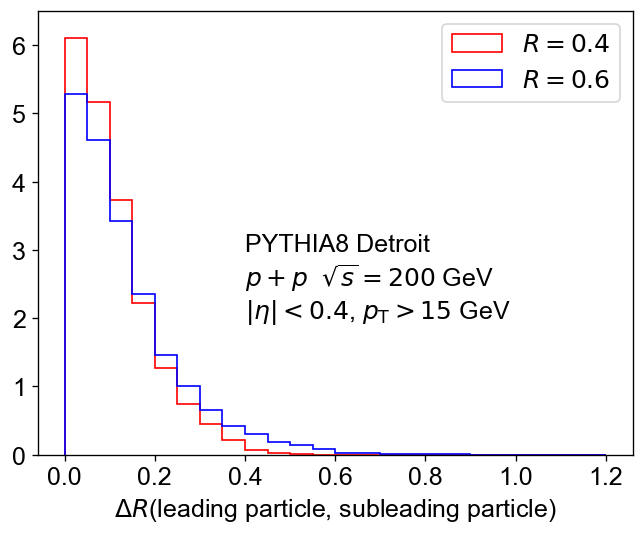

In [66]:
plt.hist(df_pythia_r04['dr'], weights=df_pythia_r04['w'], density=True, bins=np.arange(0,1.25,0.05),histtype='step',color='r',label='$R=0.4$')
plt.hist(df_pythia_r06['dr'], weights=df_pythia_r06['w'], density=True, bins=np.arange(0,1.25,0.05),histtype='step',color='b',label='$R=0.6$')
plt.text(0.4,2.0,'PYTHIA8 Detroit\n$p+p$  $\sqrt{s}=200$ GeV\n$|\eta|<0.4$, $p_\mathrm{T}>15$ GeV')
plt.xlabel('$\Delta R$(leading particle, subleading particle)')
plt.ylim(0,6.5)
plt.legend()

In [60]:
w_array = np.unique(df_pythia_r06['w'])

In [61]:
df_pythia_r06_array = [ df_pythia_r06[(df_pythia_r06.pt>15) & (df_pythia_r06.pt<20)],\
                    df_pythia_r06[(df_pythia_r06.pt>20) & (df_pythia_r06.pt<25)],\
                    df_pythia_r06[(df_pythia_r06.pt>25) & (df_pythia_r06.pt<30)],\
                    df_pythia_r06[(df_pythia_r06.pt>30) & (df_pythia_r06.pt<40)] ]

In [62]:
rc_pythia_array_r06 = []
rc_err_pythia_array_r06 = []
for i in range(0, len(df_pythia_r06_array)):
    rc_pythia_array_r06.append(getRcAndErr(df_pythia_r06_array[i], 'b')[0])
    rc_err_pythia_array_r06.append(getRcAndErr(df_pythia_r06_array[i], 'b')[1])

In [63]:
rc_pythia_array_r06

[-0.3582177573914552,
 -0.35280464080304197,
 -0.34998271632278666,
 -0.35848667474250917]

In [64]:
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
plt.rcParams['font.family'] = 'arial'
plt.rcParams['axes.unicode_minus'] = False

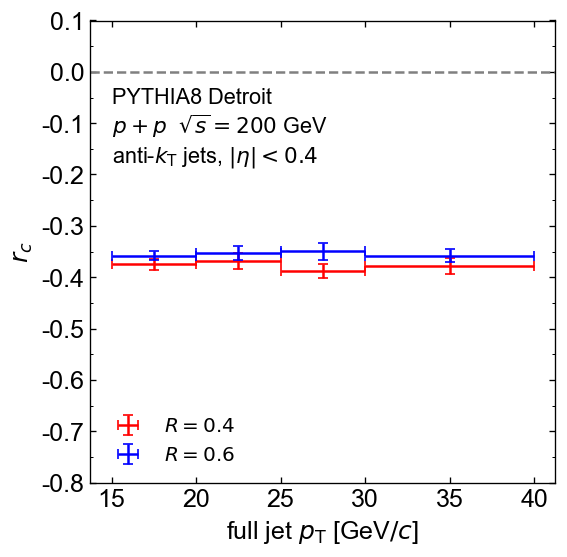

In [65]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pythia_array_r04, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pythia_array_r04, capsize=3, color='r', ls='none', label='$R = 0.4$')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pythia_array_r06, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pythia_array_r06, capsize=3, color='b', ls='none', label='$R = 0.6$')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(15,-0.175,'PYTHIA8 Detroit\n$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $|\eta|<0.4$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.8,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.show()
#plt.savefig('rc_vs_pt.png', bbox_inches='tight')
plt.savefig('rc_vs_pt.pdf', bbox_inches='tight')

Also cutting on $\Delta R_{1,2}$

In [30]:
w_array = np.unique(df_pythia_r04['w'])

In [31]:
df_pythia_r04_array = [ df_pythia_r04[(df_pythia_r04.pt>15) & (df_pythia_r04.pt<20) & (df_pythia_r04.dr<0.4)],\
                    df_pythia_r04[(df_pythia_r04.pt>20) & (df_pythia_r04.pt<25) & (df_pythia_r04.dr<0.4)],\
                    df_pythia_r04[(df_pythia_r04.pt>25) & (df_pythia_r04.pt<30) & (df_pythia_r04.dr<0.4)],\
                    df_pythia_r04[(df_pythia_r04.pt>30) & (df_pythia_r04.pt<40) & (df_pythia_r04.dr<0.4)] ]

In [32]:
rc_pythia_array_r04 = []
rc_err_pythia_array_r04 = []
for i in range(0, len(df_pythia_r04_array)):
    rc_pythia_array_r04.append(getRcAndErr(df_pythia_r04_array[i], 'b')[0])
    rc_err_pythia_array_r04.append(getRcAndErr(df_pythia_r04_array[i], 'b')[1])

In [33]:
rc_pythia_array_r04

[-0.3830573188025614,
 -0.3746221845763293,
 -0.38756521242003067,
 -0.3857130119491098]

In [34]:
w_array = np.unique(df_pythia_r06['w'])

In [35]:
df_pythia_r06_array = [ df_pythia_r06[(df_pythia_r06.pt>15) & (df_pythia_r06.pt<20) & (df_pythia_r06.dr<0.4)],\
                    df_pythia_r06[(df_pythia_r06.pt>20) & (df_pythia_r06.pt<25) & (df_pythia_r06.dr<0.4)],\
                    df_pythia_r06[(df_pythia_r06.pt>25) & (df_pythia_r06.pt<30) & (df_pythia_r06.dr<0.4)],\
                    df_pythia_r06[(df_pythia_r06.pt>30) & (df_pythia_r06.pt<40) & (df_pythia_r06.dr<0.4)] ]

In [36]:
rc_pythia_array_r06 = []
rc_err_pythia_array_r06 = []
for i in range(0, len(df_pythia_r06_array)):
    rc_pythia_array_r06.append(getRcAndErr(df_pythia_r06_array[i], 'b')[0])
    rc_err_pythia_array_r06.append(getRcAndErr(df_pythia_r06_array[i], 'b')[1])

In [37]:
rc_pythia_array_r06

[-0.36204480778435166,
 -0.35806853576200687,
 -0.36540365478400644,
 -0.36590822105510973]

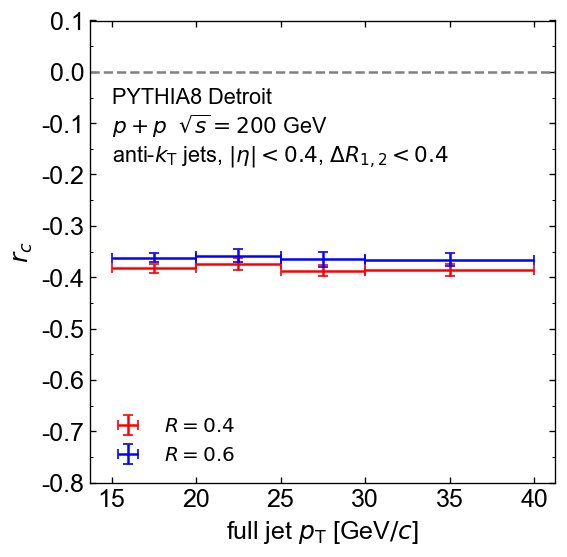

In [40]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pythia_array_r04, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pythia_array_r04, capsize=3, color='r', ls='none', label='$R = 0.4$')
plt.errorbar([17.5, 22.5, 27.5, 35], rc_pythia_array_r06, xerr=[2.5, 2.5, 2.5, 5], yerr=rc_err_pythia_array_r06, capsize=3, color='b', ls='none', label='$R = 0.6$')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]', fontsize=15)
plt.text(15,-0.175,'PYTHIA8 Detroit\n$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ jets, $|\eta|<0.4$, $\Delta R_{1,2}<0.4$', fontsize=13)
#plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.8,0.1)
plt.legend(fontsize=12, loc='lower left', frameon=False)
ax = plt.gca()
ax.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both')
ax.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
#plt.show()
#plt.savefig('rc_vs_pt.png', bbox_inches='tight')
plt.savefig('rc_vs_pt.pdf', bbox_inches='tight')